# Logistic Regression on Iris Dataset

In this lab, we implement **Logistic Regression** for classification on the **built-in Iris dataset from scikit-learn**.
We start with Binary Classification (Setosa vs Non-Setosa) and extend to Multiclass Classification (One-vs-Rest / Softmax).

#### Mathematical Foundation:
1. **Sigmoid Function**:
   $$\sigma(z) = \frac{1}{1 + e^{-z}}, \quad \text{where } z = \theta_0 + \theta_1 x_1 + \dots + \theta_n x_n = X\theta$$
2. **Cost Function (Binary Cross-Entropy)**:
   $$J(\theta) = -\frac{1}{m} \sum_{i=1}^m \left[ y^{(i)} \log(\hat{y}^{(i)}) + (1 - y^{(i)}) \log(1 - \hat{y}^{(i)}) \right]$$

### 1. Importing the necessary modules

In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report, ConfusionMatrixDisplay

### 2. Loading the built-in Iris dataset directly from scikit-learn

In [2]:
iris = load_iris(as_frame=True)
df = iris.frame
# Map integer targets (0, 1, 2) to readable species names
df['species'] = df['target'].map(dict(enumerate(iris.target_names)))
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


### 3. Inspecting class distribution

In [3]:
print(df['species'].value_counts())
df.describe()

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


---
### Part A: Binary Logistic Regression (Setosa vs Non-Setosa)
Let's first build intuition with a binary classification problem:
Is the flower Iris-setosa (1) or not (0)?

In [4]:
# Create binary target: 1 if setosa (target == 0), 0 otherwise
df_binary = df.copy()
df_binary['is_setosa'] = (df_binary['target'] == 0).astype(int)

X_bin = df_binary[['petal length (cm)', 'petal width (cm)']].values
y_bin = df_binary['is_setosa'].values
X_bin[:5], y_bin[:5]

(array([[1.4, 0.2],
        [1.4, 0.2],
        [1.3, 0.2],
        [1.5, 0.2],
        [1.4, 0.2]]),
 array([1, 1, 1, 1, 1]))

### Splitting Binary dataset into Training and Test set

In [5]:
X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(X_bin, y_bin, test_size=0.2, random_state=0)
print(f"Train size: {len(X_train_b)}, Test size: {len(X_test_b)}")

Train size: 120, Test size: 30


### Feature Scaling using StandardScaler
Logistic regression gradient descent converges faster with normalized features.

In [6]:
sc_bin = StandardScaler()
X_train_b = sc_bin.fit_transform(X_train_b)
X_test_b = sc_bin.transform(X_test_b)
X_train_b[:5]

array([[ 0.94751783,  0.736072  ],
       [ 0.38491447,  0.34752959],
       [-1.30289562, -1.33615415],
       [ 0.60995581,  0.736072  ],
       [ 1.00377816,  1.25412853]])

### Training Binary Logistic Regression Model

In [7]:
binary_classifier = LogisticRegression(random_state=0)
binary_classifier.fit(X_train_b, y_train_b)

print(f"Learned Intercept: {binary_classifier.intercept_}")
print(f"Learned Coefficients: {binary_classifier.coef_}")

Learned Intercept: [-2.74857901]
Learned Coefficients: [[-2.37768732 -2.09320492]]


### Visualizing the Sigmoid Curve & Decision Boundary

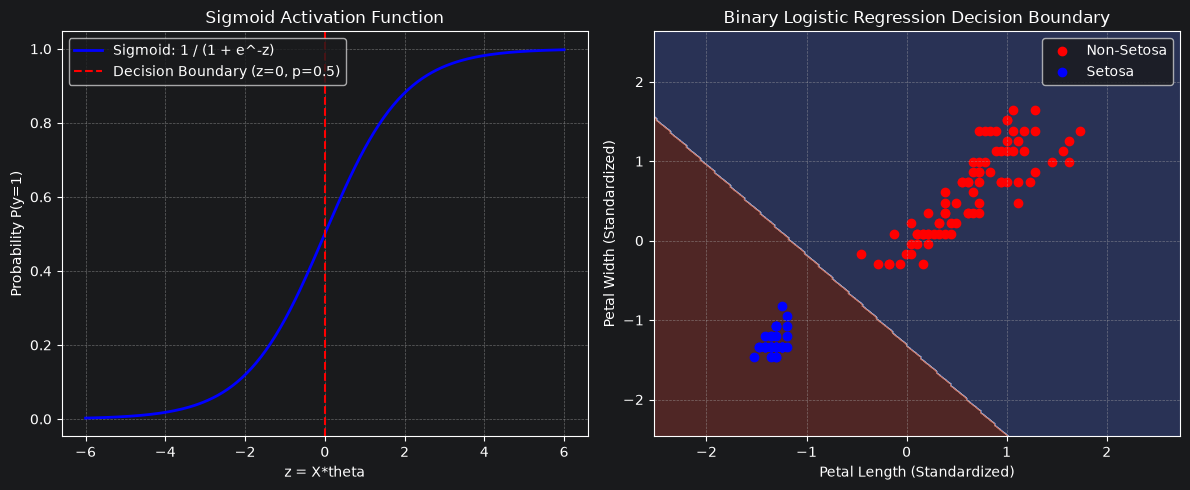

In [8]:
plt.figure(figsize=(12, 5))

# Plot 1: Sigmoid Probability curve
plt.subplot(1, 2, 1)
z_vals = np.linspace(-6, 6, 200)
sigmoid_vals = 1 / (1 + np.exp(-z_vals))
plt.plot(z_vals, sigmoid_vals, color="blue", lw=2, label="Sigmoid: 1 / (1 + e^-z)")
plt.axvline(0, color="red", linestyle="--", label="Decision Boundary (z=0, p=0.5)")
plt.title("Sigmoid Activation Function")
plt.xlabel("z = X*theta")
plt.ylabel("Probability P(y=1)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)

# Plot 2: 2D Decision boundary in feature space
plt.subplot(1, 2, 2)
x_min, x_max = X_train_b[:, 0].min() - 1, X_train_b[:, 0].max() + 1
y_min, y_max = X_train_b[:, 1].min() - 1, X_train_b[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02), np.arange(y_min, y_max, 0.02))
Z = binary_classifier.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

plt.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.coolwarm)
plt.scatter(X_train_b[y_train_b == 0, 0], X_train_b[y_train_b == 0, 1], color="red", label="Non-Setosa")
plt.scatter(X_train_b[y_train_b == 1, 0], X_train_b[y_train_b == 1, 1], color="blue", label="Setosa")
plt.title("Binary Logistic Regression Decision Boundary")
plt.xlabel("Petal Length (Standardized)")
plt.ylabel("Petal Width (Standardized)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

---
### Part B: Multiclass Logistic Regression (All 3 Iris Species)
#### Slicing X (all 4 features) and y (species target) directly from sklearn

In [9]:
X = iris.data.values
y = iris.target.values
target_names = iris.target_names

print("Classes:", target_names)
X[:5], y[:5]

Classes: ['setosa' 'versicolor' 'virginica']


(array([[5.1, 3.5, 1.4, 0.2],
        [4.9, 3. , 1.4, 0.2],
        [4.7, 3.2, 1.3, 0.2],
        [4.6, 3.1, 1.5, 0.2],
        [5. , 3.6, 1.4, 0.2]]),
 array([0, 0, 0, 0, 0]))

### Splitting into Training and Test set

In [10]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"X_train shape: {X_train.shape}, X_test shape: {X_test.shape}")

X_train shape: (120, 4), X_test shape: (30, 4)


### Feature Scaling

In [11]:
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)
X_train[:3]

array([[-1.47393679,  1.20365799, -1.56253475, -1.31260282],
       [-0.13307079,  2.99237573, -1.27600637, -1.04563275],
       [ 1.08589829,  0.08570939,  0.38585821,  0.28921757]])

### Training Multiclass Logistic Regression Model
Using Multinomial cross-entropy (Softmax)

In [12]:
classifier = LogisticRegression(random_state=42, max_iter=200)
classifier.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",200
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbf

### Predicting the Test set results

In [13]:
y_pred = classifier.predict(X_test)
results_df = pd.DataFrame({
    "Actual Class": [target_names[i] for i in y_test],
    "Predicted Class": [target_names[i] for i in y_pred]
})
results_df.head(10)

,Actual Class,Predicted Class
0,versicolor,versicolor
1,setosa,setosa
2,virginica,virginica
3,versicolor,versicolor
4,versicolor,versicolor
5,setosa,setosa
6,versicolor,versicolor
7,virginica,virginica
8,versicolor,versicolor
9,versicolor,versicolor


### Evaluating the Model Performance
Evaluation metrics from syllabus: **Confusion Matrix, Precision, Recall, F1 Score, Classification Accuracy**.

In [14]:
cm = confusion_matrix(y_test, y_pred)
accuracy = accuracy_score(y_test, y_pred)

print(f"Classification Accuracy: {accuracy * 100:.2f}%")
print()
print("Confusion Matrix:")
print(cm)
print()
print("Classification Report (Precision, Recall, F1-Score):")
print(classification_report(y_test, y_pred, target_names=target_names))

Classification Accuracy: 100.00%

Confusion Matrix:
[[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]

Classification Report (Precision, Recall, F1-Score):
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



### Visualizing the Confusion Matrix

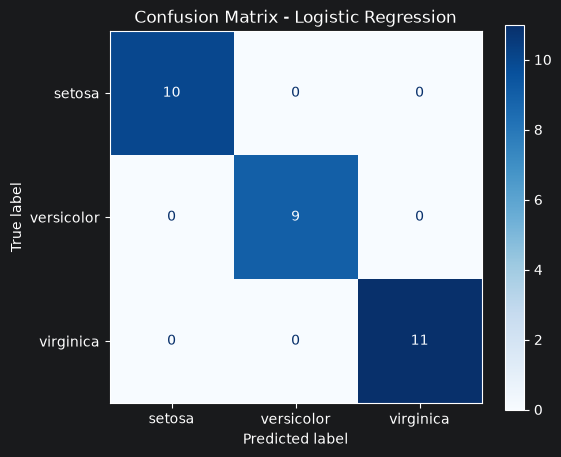

In [15]:
fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=target_names)
disp.plot(cmap=plt.cm.Blues, ax=ax)
plt.title("Confusion Matrix - Logistic Regression")
plt.grid(False)
plt.show()